# Rossmann Store Sales Analysis

## Project Overview

This project analyzes historical sales data from Rossmann drug stores to identify sales patterns, explore the relationship between promotions and sales, and build a model to predict daily sales.

**Objectives**
- Explore sales trends across time, stores, and promotional activity.
- Clean and prepare the data for analysis.
- Identify key patterns and factors associated with sales.
- Build and compare regression models for daily sales prediction.

**Tools:** Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn, and Jupyter Notebook.

**Dataset:** Rossmann Store Sales dataset from Kaggle.

**Project workflow:** Data Loading → Data Cleaning → Feature Engineering → EDA → Regression Modeling → Evaluation → Conclusion.

## 1. Data Loading and Initial Inspection

In [1]:
import pandas as pd,numpy as np
import matplotlib.pyplot as plt,seaborn as sns

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
store = pd.read_csv('store.csv')

C:\Users\Aravind.DESKTOP-UBQ52SC\AppData\Local\Temp\ipykernel_11616\2817523562.py:1: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv('train.csv')


**Data-quality check:** Review the distribution of daily customer counts.

In [3]:
train['Customers'].describe()

count    1.017209e+06
mean     6.331459e+02
std      4.644117e+02
min      0.000000e+00
25%      4.050000e+02
50%      6.090000e+02
75%      8.370000e+02
max      7.388000e+03
Name: Customers, dtype: float64

**Data-quality check:** Review the distribution of daily sales, including zeros and extreme values.

In [4]:
train['Sales'].describe()

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

**Data-quality check:** Count open and closed store-day records.

In [5]:
train['Open'].value_counts()

Open
1    844392
0    172817
Name: count, dtype: int64

**Data-quality check:** Check distinct state-holiday values before standardizing the column.

In [6]:
train['StateHoliday'].unique()

array(['0', 'a', 'b', 'c', 0], dtype=object)

**Data-quality check:** Inspect the distribution of state-holiday categories, including missing values.

In [7]:
train['StateHoliday'].value_counts(dropna=False)

StateHoliday
0    855087
0    131072
a     20260
b      6690
c      4100
Name: count, dtype: int64

**Data-quality check:** Initial numerical summary of the training dataset.

In [8]:
train.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


In [9]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Store shape:", store.shape)

Train shape: (1017209, 9)
Test shape: (41088, 8)
Store shape: (1115, 10)


In [10]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [11]:
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [12]:
test.head()

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0


In [13]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  str   
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), str(1)
memory usage: 79.5+ MB


In [14]:
store.info()

<class 'pandas.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   str    
 2   Assortment                 1115 non-null   str    
 3   CompetitionDistance        1112 non-null   float64
 4   CompetitionOpenSinceMonth  761 non-null    float64
 5   CompetitionOpenSinceYear   761 non-null    float64
 6   Promo2                     1115 non-null   int64  
 7   Promo2SinceWeek            571 non-null    float64
 8   Promo2SinceYear            571 non-null    float64
 9   PromoInterval              571 non-null    str    
dtypes: float64(5), int64(2), str(3)
memory usage: 98.0 KB


## 2. Data Cleaning and Quality Checks

In [15]:
train['StateHoliday'] = train['StateHoliday'].astype(str)

In [16]:
train['Date'] = pd.to_datetime(train['Date'])

In [17]:
train[['Date', 'StateHoliday']].dtypes

Date            datetime64[us]
StateHoliday               str
dtype: object

In [18]:
train['StateHoliday'].value_counts()

StateHoliday
0    986159
a     20260
b      6690
c      4100
Name: count, dtype: int64

In [19]:
store.isnull().sum()

Store                          0
StoreType                      0
Assortment                     0
CompetitionDistance            3
CompetitionOpenSinceMonth    354
CompetitionOpenSinceYear     354
Promo2                         0
Promo2SinceWeek              544
Promo2SinceYear              544
PromoInterval                544
dtype: int64

In [20]:
store[store['CompetitionDistance'].isnull()]

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
290,291,d,a,NaN,NaN,NaN,0,NaN,NaN,NaN
621,622,a,c,NaN,NaN,NaN,0,NaN,NaN,NaN
878,879,d,a,NaN,NaN,NaN,1,5.0,2013.0,"Feb,May,Aug,Nov"


In [21]:
store[store['CompetitionOpenSinceMonth'].isnull() & 
      store['CompetitionOpenSinceYear'].isnull()]

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
11,12,a,c,1070.0,NaN,NaN,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
12,13,d,a,310.0,NaN,NaN,1,45.0,2009.0,"Feb,May,Aug,Nov"
15,16,a,c,3270.0,NaN,NaN,0,NaN,NaN,NaN
18,19,a,c,3240.0,NaN,NaN,1,22.0,2011.0,"Mar,Jun,Sept,Dec"
21,22,a,a,1040.0,NaN,NaN,1,22.0,2012.0,"Jan,Apr,Jul,Oct"
...,...,...,...,...,...,...,...,...,...,...
1095,1096,a,c,1130.0,NaN,NaN,1,10.0,2014.0,"Mar,Jun,Sept,Dec"
1099,1100,a,a,540.0,NaN,NaN,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [22]:
pd.crosstab(store['Promo2'], store['PromoInterval'].isnull())

PromoInterval,False,True
Promo2,,
0,0,544
1,571,0


In [23]:
store['Store'].nunique()

1115

In [24]:
store['Store'].duplicated().sum()

np.int64(0)

In [25]:
train['Store'].nunique()

1115

## 3. Data Preparation and Feature Engineering

In [26]:
# Combine daily sales records with store-level characteristics.
df = train.merge(store, on = 'Store',how = 'left')

In [27]:
print("Train rows:", len(train))
print("Merged rows:", len(df))
print("Merged columns:", df.shape[1])

Train rows: 1017209
Merged rows: 1017209
Merged columns: 18


In [28]:
# Extract calendar features to analyze seasonal and weekly sales patterns
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['WeekOfYear'] = df['Date'].dt.isocalendar().week.astype(int)
df['IsWeekend'] = df['DayOfWeek'].isin([6, 7]).astype(int)

In [29]:
df['CompetitionOpenDate'] = pd.to_datetime(
    dict(
        year=df['CompetitionOpenSinceYear'],
        month=df['CompetitionOpenSinceMonth'],
        day=1
    ),
    errors='coerce'
)

In [30]:
(df['CompetitionOpenDate'] > df['Date']).sum()

np.int64(84666)

In [31]:
df['CompetitionAgeMonths'] = (
    (df['Date'].dt.year - df['CompetitionOpenDate'].dt.year) * 12
    + (df['Date'].dt.month - df['CompetitionOpenDate'].dt.month)
)

In [32]:
df.loc[
    df['CompetitionAgeMonths'] < 0,
    'CompetitionAgeMonths'
] = 0

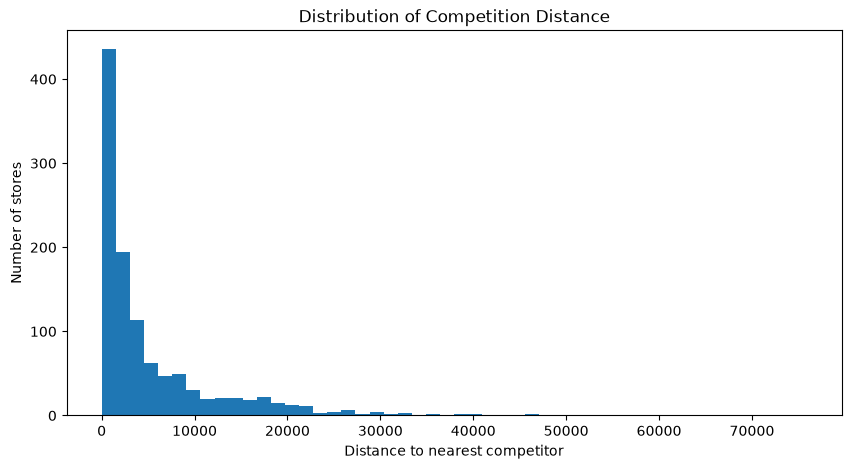

In [33]:
store['CompetitionDistance'].plot(
    kind='hist',
    bins=50,
    figsize=(10, 5),
    title='Distribution of Competition Distance'
)

plt.xlabel('Distance to nearest competitor')
plt.ylabel('Number of stores')
plt.show()

In [34]:
# Fill missing competitor distances with the median across stores.
df['CompetitionDistance'] = df['CompetitionDistance'].fillna(store['CompetitionDistance'].median())

## 4. Exploratory Data Analysis (EDA)

In [35]:
# Analyze and model sales only for records where the store was open.
df_open = df[df['Open'] == 1].copy()

In [36]:
print("Original dataset:", df.shape)
print("Open-store dataset:", df_open.shape)
print("Date range:", df_open['Date'].min(), "to", df_open['Date'].max())

Original dataset: (1017209, 25)
Open-store dataset: (844392, 25)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00


In [37]:
df_open.groupby('Year')['Sales'].agg(['count', 'mean', 'sum'])

,count,mean,sum
Year,,,
2013,337943,6814.392025,2302876084
2014,310417,7025.404201,2180804896
2015,196032,7088.126648,1389499643


### Sales Trends Over Time

Compare average daily sales by month and year. Note that 2015 contains data only through July.

## 4. Exploratory Data Analysis (EDA)

This section follows a structured workflow:
1. Inspect dataset distributions and data quality.
2. Explore sales trends over time.
3. Compare sales and customer activity across promotions and weekdays.
4. Compare store types, assortment categories, and store-level performance.

The aim is to identify patterns that inform the sales prediction task, not to claim that observed relationships are causal.

In [38]:
monthly_sales = (df_open.groupby(['Year', 'Month'])['Sales'].agg(['mean', 'sum', 'count']).reset_index())

monthly_sales.head(15)

,Year,Month,mean,sum,count
0,2013,1,6239.641380,180132207,28869
1,2013,2,6428.597796,171534275,26683
2,2013,3,7212.834110,201180369,27892
3,2013,4,6579.319656,183431432,27880
4,2013,5,7076.217960,185411063,26202
5,2013,6,6467.051428,180702351,27942
6,2013,7,6923.154611,208843882,30166
7,2013,8,6595.927627,198042727,30025
8,2013,9,6363.388121,178053963,27981
9,2013,10,6473.347016,187662330,28990


In [39]:
monthly_comparison = monthly_sales.pivot(
    index='Month',
    columns='Year',
    values='mean'
).round(2)

monthly_comparison

Year,2013,2014,2015
Month,,,
1,6239.64,6539.40,6913.18
2,6428.60,6678.04,6660.27
3,7212.83,6654.02,7071.24
4,6579.32,7226.78,7349.11
5,7076.22,6948.12,7308.50
6,6467.05,7250.66,7295.62
7,6923.15,6891.48,7033.34
8,6595.93,6714.31,NaN
9,6363.39,6756.59,NaN


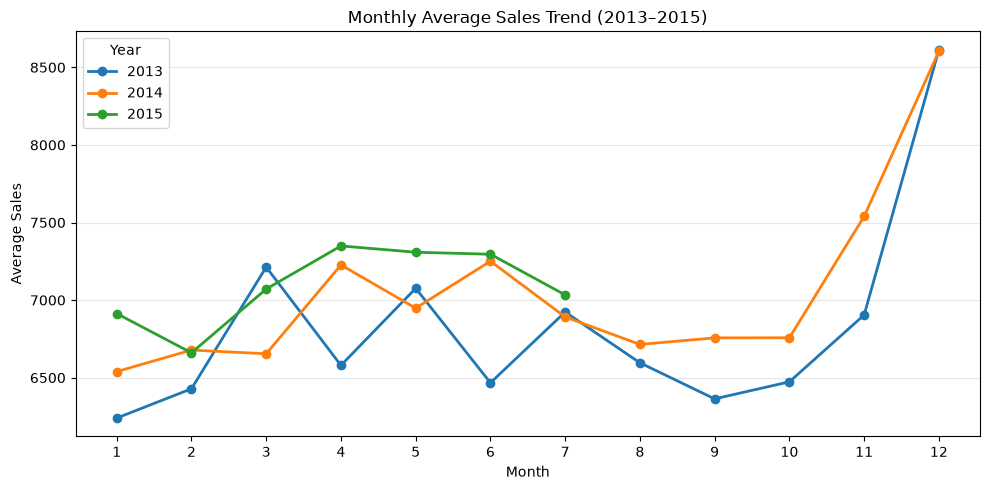

In [40]:
monthly_comparison.plot(marker='o', figsize=(10, 5), linewidth=2)

plt.title('Monthly Average Sales Trend (2013–2015)')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.xticks(range(1, 13))
plt.grid(axis='y', alpha=0.3)
plt.legend(title='Year')
plt.tight_layout()
plt.show()

**How to interpret these trends:** Compare months across years, and remember that 2015 covers only January–July in this dataset.

### Promotion Analysis

Compare sales on promotional and non-promotional days. These are associations in the observed data, not proof of causation.

In [41]:
df_open.groupby('Promo')['Sales'].mean().round(2)

Promo
0    5929.41
1    8228.28
Name: Sales, dtype: float64

**Interpretation note:** Compare average sales on promotional and non-promotional days. This shows an association in the observed data, not proof that promotions caused the difference.

In [42]:
store_promo = df_open.groupby(['StoreType', 'Promo'])['Sales'].mean().unstack()

store_promo['Increase %'] = ((store_promo[1] - store_promo[0]) / store_promo[0] * 100).round(2)

store_promo

Promo,0,1,Increase %
StoreType,,,
a,5808.500091,8304.102317,42.96
b,9566.861686,11307.994108,18.20
c,6028.063255,8041.995526,33.41
d,5855.268289,8017.828656,36.93


In [43]:
weekday_promo = df_open.groupby(['DayOfWeek', 'Promo'])['Sales'].mean().unstack()

weekday_promo['Increase %'] = ((weekday_promo[1] - weekday_promo[0])/ weekday_promo[0] * 100).round(2)

weekday_promo

Promo,0,1,Increase %
DayOfWeek,,,
1,6222.521495,9772.784369,57.06
2,5716.241087,8277.201522,44.80
3,5617.044778,7685.077816,36.82
4,5749.837412,7598.070761,32.14
5,6344.030127,7744.066219,22.07
6,5874.840238,NaN,NaN
7,8224.723908,NaN,NaN


In [44]:
df_open.groupby('Assortment')['Sales'].mean().round(2)

Assortment
a    6621.02
b    8639.35
c    7300.53
Name: Sales, dtype: float64

In [45]:
assortment_promo = df_open.groupby(['Assortment', 'Promo'])['Sales'].mean().unstack()

assortment_promo['Increase %'] = ((assortment_promo[1] - assortment_promo[0])/ assortment_promo[0] * 100).round(2)

assortment_promo

Promo,0,1,Increase %
Assortment,,,
a,5559.715325,7933.446898,42.70
b,8398.199882,9030.074346,7.52
c,6291.668238,8549.346130,35.88


In [46]:
df_open.groupby('Promo')[['Sales', 'Customers']].mean().round(2)

,Sales,Customers
Promo,,
0,5929.41,696.86
1,8228.28,844.43


### Store-Level Performance

Identify stores with the highest and lowest average daily sales, then compare performance across store types.

In [47]:
store_sales = df_open.groupby('Store')['Sales'].agg(['mean', 'sum', 'count']).round(2)

store_sales = store_sales.sort_values('mean', ascending=False)

store_sales.head(10)

,mean,sum,count
Store,,,
817,21757.48,17057867,784
262,20718.52,19516842,942
1114,20666.56,16202585,784
251,19123.07,14896870,779
842,18574.80,11553523,622
513,18179.09,14252406,784
562,17969.56,16927322,942
788,17961.91,14082141,784
383,17294.72,13489879,780


In [48]:
store_sales.sort_values('mean').head(10)

,mean,sum,count
Store,,,
307,2703.74,2114322,782
543,2790.38,2179287,781
198,2900.60,2268273,782
208,2936.29,2302052,784
841,2972.61,2318635,780
254,3005.98,2341661,779
794,3083.81,2405374,780
219,3133.71,2441162,779
210,3193.98,2488114,779


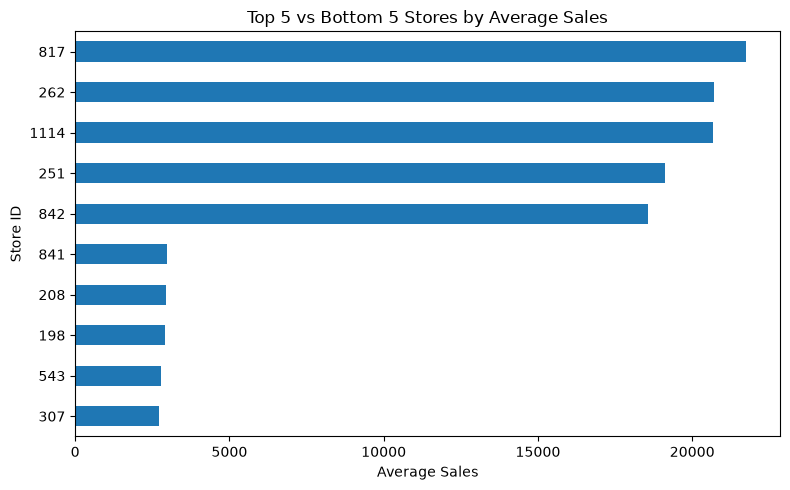

In [49]:
top5 = store_sales.head(5)['mean']
bottom5 = store_sales.tail(5)['mean']

comparison = pd.concat([top5, bottom5]).sort_values()

comparison.plot(kind='barh', figsize=(8, 5))

plt.title('Top 5 vs Bottom 5 Stores by Average Sales')
plt.xlabel('Average Sales')
plt.ylabel('Store ID')
plt.tight_layout()
plt.show()

In [50]:
df_open.groupby('StoreType')['Sales'].mean().round(2)

StoreType
a     6925.17
b    10231.41
c     6932.51
d     6822.14
Name: Sales, dtype: float64

In [51]:
store_details = df[['Store', 'StoreType', 'Assortment']].drop_duplicates()

store_details = store_details.set_index('Store')

store_details.loc[[817, 262, 1114, 307, 543]]

,StoreType,Assortment
Store,,
817,a,a
262,b,a
1114,a,c
307,a,a
543,c,a


In [52]:
store_type_summary = df_open.groupby('StoreType').agg(
    Average_Sales=('Sales', 'mean'),
    Total_Sales=('Sales', 'sum'),
    Number_of_Stores=('Store', 'nunique')
).round(2)

store_type_summary

,Average_Sales,Total_Sales,Number_of_Stores
StoreType,,,
a,6925.17,3165334859,602
b,10231.41,159231395,17
c,6932.51,783221426,148
d,6822.14,1765392943,348


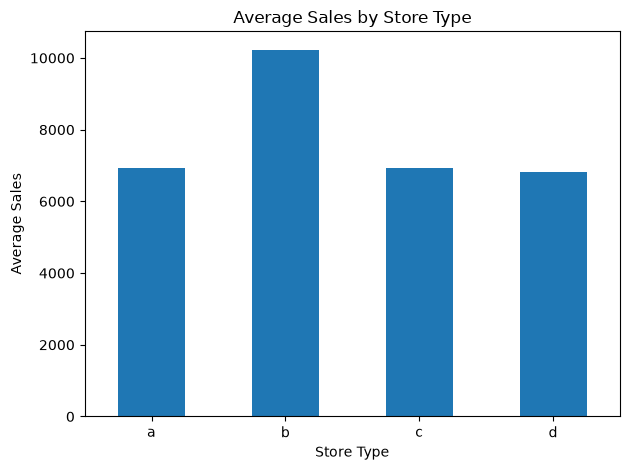

In [53]:
store_type_summary['Average_Sales'].plot(kind='bar')

plt.title('Average Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Average Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Regression Modeling: Daily Sales Prediction

**Objective:** Predict daily sales for open Rossmann stores using historical sales patterns, store characteristics, promotional activity, and calendar features.

**Models used:**
- Linear Regression — baseline model
- Random Forest Regressor — comparison model

**Evaluation metrics:** Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

**Validation approach:** Train on historical data through June 2015 and evaluate predictions on July 2015.


## 1. Feature Selection


In [54]:
features = [
    'Store',
    'DayOfWeek',
    'Month',
    'Year',
    'Promo',
    'StateHoliday',
    'SchoolHoliday',
    'StoreType',
    'Assortment'
]

X = df_open[features]
y = df_open['Sales']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (844392, 9)
Target shape: (844392,)



## 2. Train-Validation Split


In [55]:
train_data = df_open[df_open['Date'] <= '2015-06-30']
valid_data = df_open[df_open['Date'] > '2015-06-30']

X_train = train_data[features]
y_train = train_data['Sales']

X_valid = valid_data[features]
y_valid = valid_data['Sales']

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))

Training rows: 814204
Validation rows: 30188



## 3. Encoding Categorical Variables


In [56]:
X_train_encoded = pd.get_dummies(X_train, columns=['StateHoliday', 'StoreType', 'Assortment'])

X_valid_encoded = pd.get_dummies(X_valid, columns=['StateHoliday', 'StoreType', 'Assortment'])

X_valid_encoded = X_valid_encoded.reindex(columns=X_train_encoded.columns,fill_value=0)

print("Training features:", X_train_encoded.shape)
print("Validation features:", X_valid_encoded.shape)

Training features: (814204, 17)
Validation features: (30188, 17)


### 5.4 Model Training and Evaluation

Two regression models are trained and compared using MAE and RMSE to identify which predicts daily sales more accurately.

### 4.1 Linear Regression
A baseline model used to establish initial prediction performance.

### 4.2 Random Forest Regressor
A tree-based model used to capture more complex patterns in sales data.

In [57]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train_encoded, y_train)

predictions = model.predict(X_valid_encoded)

In [58]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 1974.8
RMSE: 2625.88


In [59]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_encoded, y_train)

rf_predictions = rf_model.predict(X_valid_encoded)

In [60]:
rf_mae = mean_absolute_error(y_valid, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_predictions))

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))

Random Forest MAE: 1463.46
Random Forest RMSE: 2031.77


### 5.5 Model Performance Comparison

| Model | MAE | RMSE |
|---|---:|---:|
| Linear Regression | 1,974.80 | 2,625.88 |
| Random Forest Regressor | 1,463.46 | 2,031.77 |

The Random Forest Regressor achieved lower MAE and RMSE than Linear Regression, indicating better prediction accuracy on the July 2015 validation dataset.

In [61]:
# Rank features by their contribution to the Random Forest predictions.
importance = pd.Series(rf_model.feature_importances_,index=X_train_encoded.columns).sort_values(ascending=False)

importance.head(10)

Store           0.411008
Promo           0.271219
DayOfWeek       0.101421
Month           0.055268
StoreType_b     0.047336
Assortment_c    0.023829
StoreType_a     0.022742
Assortment_a    0.017010
StoreType_d     0.010875
Year            0.009838
dtype: float64

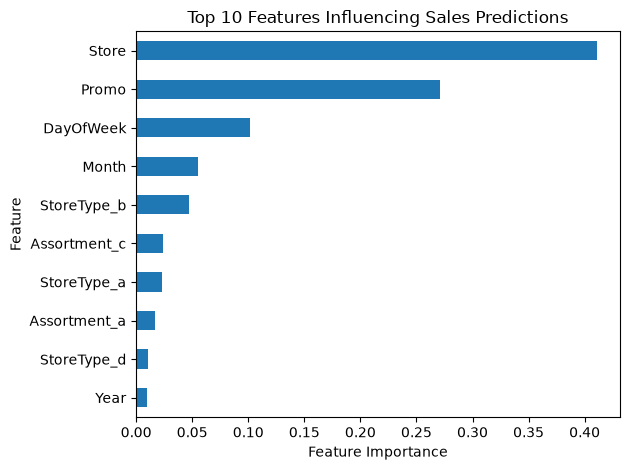

In [62]:
importance.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Features Influencing Sales Predictions')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 6. Conclusion

- Sales varied by store, weekday, month, and promotional activity.
- Average sales and customer counts were higher on promotional days in the observed data.
- Random Forest outperformed Linear Regression, reducing MAE by approximately **25.9%**.
- Store ID, promotion status, and day of the week were among the most influential features in the Random Forest model.

**Final takeaway:** The analysis demonstrates how retail sales data can be explored and used to build a regression model for daily sales prediction.

**Limitation:** The model was evaluated on open-store records from July 2015. The observed association between promotions and sales does not, by itself, prove that promotions caused the increase.